# Genomics of Drug Sensitivity in Cancer (GDSC) Project Analysis Notebook

In [2]:
# Importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec
import seaborn as sns
import math
import tkinter as tk

In [3]:
# Set global visual theme
sns.set_theme(style="whitegrid")

In [4]:
# Define a helper function to dynamically adjust figure size based on screen resolution
def get_screen_size():
    # Get screen size
    root = tk.Tk()
    screen_width = root.winfo_screenwidth()
    screen_height = root.winfo_screenheight()
    root.destroy()

    # Calculate figure size (e.g., 70% of screen)
    dpi = 100
    fig_width = (screen_width * 0.7) / dpi
    fig_height = (screen_height * 0.7) / dpi

    return fig_width, fig_height

SCREEN_W, SCREEN_H = get_screen_size()
TARGET = "TARGET"

# 1. Data Loading

In [5]:
# Loading the GDSC Excel dataset into a Pandas DataFrame
gdsc = pd.read_excel("https://github.com/HackBio-Internship/public_datasets/raw/refs/heads/main/GDSC.xlsx")

# 2. Data Inspection

In [7]:
# Display the first few rows of the dataset to preview its structure
print(gdsc.shape)
gdsc.head()

(162103, 19)


,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY
0,683667,PFSK-1,MB,1003,Camptothecin,-1.463887,0.930220,0.433123,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
1,687448,COLO-829,SKCM,1003,Camptothecin,-1.235034,0.867348,0.557727,skin,melanoma,SKCM,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
2,687455,RT4,BLCA,1003,Camptothecin,-2.963191,0.821438,-0.383200,urogenital_system,Bladder,BLCA,MSS/MSI-L,D/F12,Adherent,Y,Y,Y,TOP1,DNA replication
3,687457,SW780,BLCA,1003,Camptothecin,-1.449138,0.905050,0.441154,urogenital_system,Bladder,BLCA,MSS/MSI-L,D/F12,Adherent,Y,Y,Y,TOP1,DNA replication
4,687459,TCCSUP,BLCA,1003,Camptothecin,-2.350633,0.843430,-0.049682,urogenital_system,Bladder,BLCA,MSS/MSI-L,D/F12,Adherent,Y,Y,Y,TOP1,DNA replication


In [8]:
# Display dataset information including column types and non-null counts
gdsc.info()

<class 'pandas.DataFrame'>
RangeIndex: 162103 entries, 0 to 162102
Data columns (total 19 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   COSMIC_ID                                162103 non-null  int64  
 1   CELL_LINE_NAME                           162103 non-null  str    
 2   TCGA_DESC                                162103 non-null  str    
 3   DRUG_ID                                  162103 non-null  int64  
 4   DRUG_NAME                                162103 non-null  str    
 5   LN_IC50                                  162103 non-null  float64
 6   AUC                                      162103 non-null  float64
 7   Z_SCORE                                  162103 non-null  float64
 8   GDSC Tissue descriptor 1                 162103 non-null  str    
 9   GDSC Tissue descriptor 2                 162103 non-null  str    
 10  Cancer Type (matching TCGA label)        16

In [9]:
# Count the number of unique values in each column
gdsc.nunique()

COSMIC_ID                                     737
CELL_LINE_NAME                                737
TCGA_DESC                                      30
DRUG_ID                                       254
DRUG_NAME                                     246
LN_IC50                                    159646
AUC                                        109624
Z_SCORE                                    158203
GDSC Tissue descriptor 1                       17
GDSC Tissue descriptor 2                       33
Cancer Type (matching TCGA label)              30
Microsatellite instability Status (MSI)         2
Screen Medium                                   2
Growth Properties                               3
CNA                                             2
Gene Expression                                 2
Methylation                                     2
TARGET                                        183
TARGET_PATHWAY                                 23
dtype: int64

In [10]:
# Generate descriptive statistics for numerical variables
gdsc.describe()

,COSMIC_ID,DRUG_ID,LN_IC50,AUC,Z_SCORE
count,1.621030e+05,162103.000000,162103.000000,162103.000000,162103.000000
mean,9.857634e+05,1554.527603,2.822644,0.879924,0.037711
std,2.240213e+05,406.964712,2.836231,0.148592,0.999098
min,6.836670e+05,1003.000000,-8.642551,0.006282,-6.909716
25%,9.059780e+05,1086.000000,1.476170,0.845967,-0.615884
50%,9.092570e+05,1598.000000,3.271447,0.941467,0.048930
75%,1.240143e+06,1910.000000,4.767629,0.973917,0.686466
max,1.674021e+06,2499.000000,13.820189,0.998904,7.978776


# 3. Data Quality Assessment

In [11]:
# Check for missing values across all columns
gdsc.isnull().sum()

COSMIC_ID                                  0
CELL_LINE_NAME                             0
TCGA_DESC                                  0
DRUG_ID                                    0
DRUG_NAME                                  0
LN_IC50                                    0
AUC                                        0
Z_SCORE                                    0
GDSC Tissue descriptor 1                   0
GDSC Tissue descriptor 2                   0
Cancer Type (matching TCGA label)          0
Microsatellite instability Status (MSI)    0
Screen Medium                              0
Growth Properties                          0
CNA                                        0
Gene Expression                            0
Methylation                                0
TARGET                                     0
TARGET_PATHWAY                             0
dtype: int64

In [12]:
# Identify duplicate combinations of cell lines and drugs
# check for duplicates
gdsc.duplicated(subset=['CELL_LINE_NAME', 'DRUG_NAME']).sum()

np.int64(4290)

In [13]:
gdsc.duplicated(subset=["CELL_LINE_NAME", "DRUG_NAME"])

0         False
1         False
2         False
3         False
4         False
          ...  
162098    False
162099    False
162100    False
162101    False
162102    False
Length: 162103, dtype: bool

In [14]:
# Examine whether duplicate drug-cell line pairs differ in other biological variables
#Checking for variations in the other columns for the duplicate combinations
cols_to_check = [
    'Microsatellite instability Status (MSI)',
    'CNA',
    'Gene Expression',
    'Methylation',
    'Screen Medium',
    'Growth Properties',
    'TARGET',
    'TARGET_PATHWAY',
    'GDSC Tissue descriptor 1',
    'GDSC Tissue descriptor 2',
    'Cancer Type (matching TCGA label)'
]

gdsc.groupby(['COSMIC_ID', 'DRUG_NAME'])[cols_to_check].nunique().max()

Microsatellite instability Status (MSI)    1
CNA                                        1
Gene Expression                            1
Methylation                                1
Screen Medium                              1
Growth Properties                          1
TARGET                                     1
TARGET_PATHWAY                             1
GDSC Tissue descriptor 1                   1
GDSC Tissue descriptor 2                   1
Cancer Type (matching TCGA label)          1
dtype: int64

In [15]:
# Compare whether TCGA_DESC matches the TCGA cancer label column
(gdsc['TCGA_DESC'] == gdsc['Cancer Type (matching TCGA label)']).all()

np.False_

In [16]:
gdsc[['TCGA_DESC', 'Cancer Type (matching TCGA label)']].head(100)

,TCGA_DESC,Cancer Type (matching TCGA label)
0,MB,MB
1,SKCM,SKCM
2,BLCA,BLCA
3,BLCA,BLCA
4,BLCA,BLCA
...,...,...
95,BLCA,BLCA
96,LUSC,LUSC
97,ESCA,ESCA
98,LUSC,LUSC


In [17]:
# Extract rows where TCGA_DESC differs from the matching TCGA cancer label
mask = gdsc['TCGA_DESC'] != gdsc['Cancer Type (matching TCGA label)']

gdsc.loc[mask, ['TCGA_DESC', 'Cancer Type (matching TCGA label)']]

,TCGA_DESC,Cancer Type (matching TCGA label)
145,COREAD,COAD/READ
146,COREAD,COAD/READ
148,COREAD,COAD/READ
168,COREAD,COAD/READ
169,COREAD,COAD/READ
...,...,...
162009,COREAD,COAD/READ
162099,COREAD,COAD/READ
162100,COREAD,COAD/READ
162101,COREAD,COAD/READ


#### Multiple duplicate drug–cell line combinations were detected. Examination of associated biological variables showed that these records likely represent repeated measurements or screenings rather than distinct biological samples. Therefore, duplicates were retained to preserve available experimental information.

# Exploratory Data Analysis

## Univariate Analysis

### Continuous Variables

In [18]:
# Generate visualization for exploratory data analysis
def plot_distribution(data: pd.DataFrame = None, columns: list[str] = None):
    if data is None or columns is None:
        print("Missing dataframe or columns")
        return

    n = len(columns)
    n_cols = min(n, 3)
    n_rows = math.ceil(n / n_cols)

    figure = plt.figure(figsize=(SCREEN_W, SCREEN_H / n))
    outer_grid = GridSpec(n_rows, n_cols, wspace=.25, hspace=.35)
    
    for i, column in enumerate(columns):
        r, c = divmod(i, n_cols)
        
        inner_grid = GridSpecFromSubplotSpec(
            nrows=2, 
            ncols=1, 
            subplot_spec=outer_grid[r, c],
            height_ratios=[3, 1],
            hspace=.05
        )

        # --- Histogram
        hist_axe = figure.add_subplot(inner_grid[0])
        sns.histplot(data[column], bins=30, ax=hist_axe, color='skyblue')

        # Compute mean & median
        mean_val = data[column].mean()
        median_val = data[column].median()

        # Add vertical lines
        hist_axe.axvline(mean_val, color='blue', linestyle='--',
                         label=f'Mean: {mean_val:.2f}')
        hist_axe.axvline(median_val, color='red', linestyle='-',
                         label=f'Median: {median_val:.2f}')

        hist_axe.set_title(f"Distribution of {column}")
        hist_axe.set_xlabel("")
        hist_axe.legend()

        # --- Boxplot
        box_axe = figure.add_subplot(inner_grid[1])
        sns.boxplot(x=data[column].dropna(), ax=box_axe, color='skyblue')
        box_axe.set_xlabel(column)
        
    plt.show()

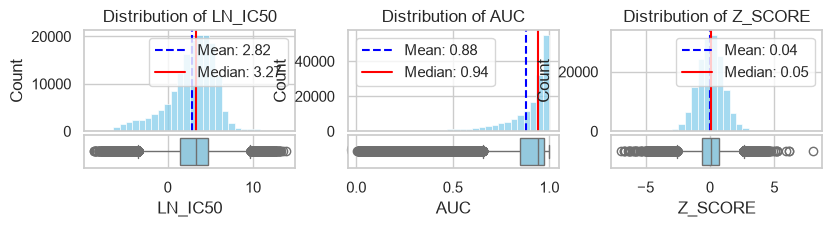

In [19]:
# Generate visualization for exploratory data analysis
continuous = gdsc.select_dtypes('float').columns
plot_distribution(data=gdsc, columns=continuous)

#### LN_IC50, AUC, and Z_SCORE show varying distributions across the dataset. The presence of skewness and outliers suggests that drug responses differ substantially between cancer cell lines and treatments.

### Discrete / Categorical Variables

In [21]:
identifiers = ["COSMIC_ID", "DRUG_ID", "DRUG_NAME", "CELL_LINE_NAME"] + ["TARGET"]
discretes = gdsc.select_dtypes(exclude='float').columns.difference(identifiers)

In [24]:
# Generate visualization for exploratory data analysis
def plot_proportions(data: pd.DataFrame = None, columns: list[str] = None, show_pct=True, n_cols=3):
    if data is None or columns is None:
        print("Missing Dataframe or columns")
        return
    
    n = len(columns)
    n_cols = min(n_cols, n)
    n_rows = math.ceil(n / n_cols)
    
    figure, axes = plt.subplots(ncols=n_cols,nrows=n_rows,figsize=(20, n_rows * 6),constrained_layout=True)
    
    axes = axes.flatten() if isinstance(axes, np.ndarray) else [axes]
    
    for i, column in enumerate(columns):
        value_counts = data[column].value_counts().sort_index()
        
        bars = axes[i].bar(
            value_counts.index.astype(str),
            value_counts.values,
            color="steelblue",
            edgecolor="black"
        )
        axes[i].set_title(column)
        axes[i].set_ylabel("Count")
        # axes[i].tick_params(axis="x", rotation=75)
        axes[i].set_xticks(range(len(value_counts)))
        axes[i].set_xticklabels(
            value_counts.index.astype(str),
            rotation=45,
            ha="right",
            fontsize=10
        )

        axes[i].set_ylim(0, value_counts.values.max() * 1.15)
        
        if show_pct:
            total = value_counts.sum()
            for bar, val in zip(bars, value_counts.values):
                pct = f"{(val / total) * 100:.1f}%"
                axes[i].text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height(),
                    pct,
                    ha="center",
                    va="bottom",
                    fontsize=8,
                    rotation=0,
                )
     # Hide unused subplots
    for i in range(len(columns), len(axes)):
        axes[i].set_visible(False)

    # remove plt.tight_layout() if using constrained_layout=True above, it's more robust
    plt.show()  

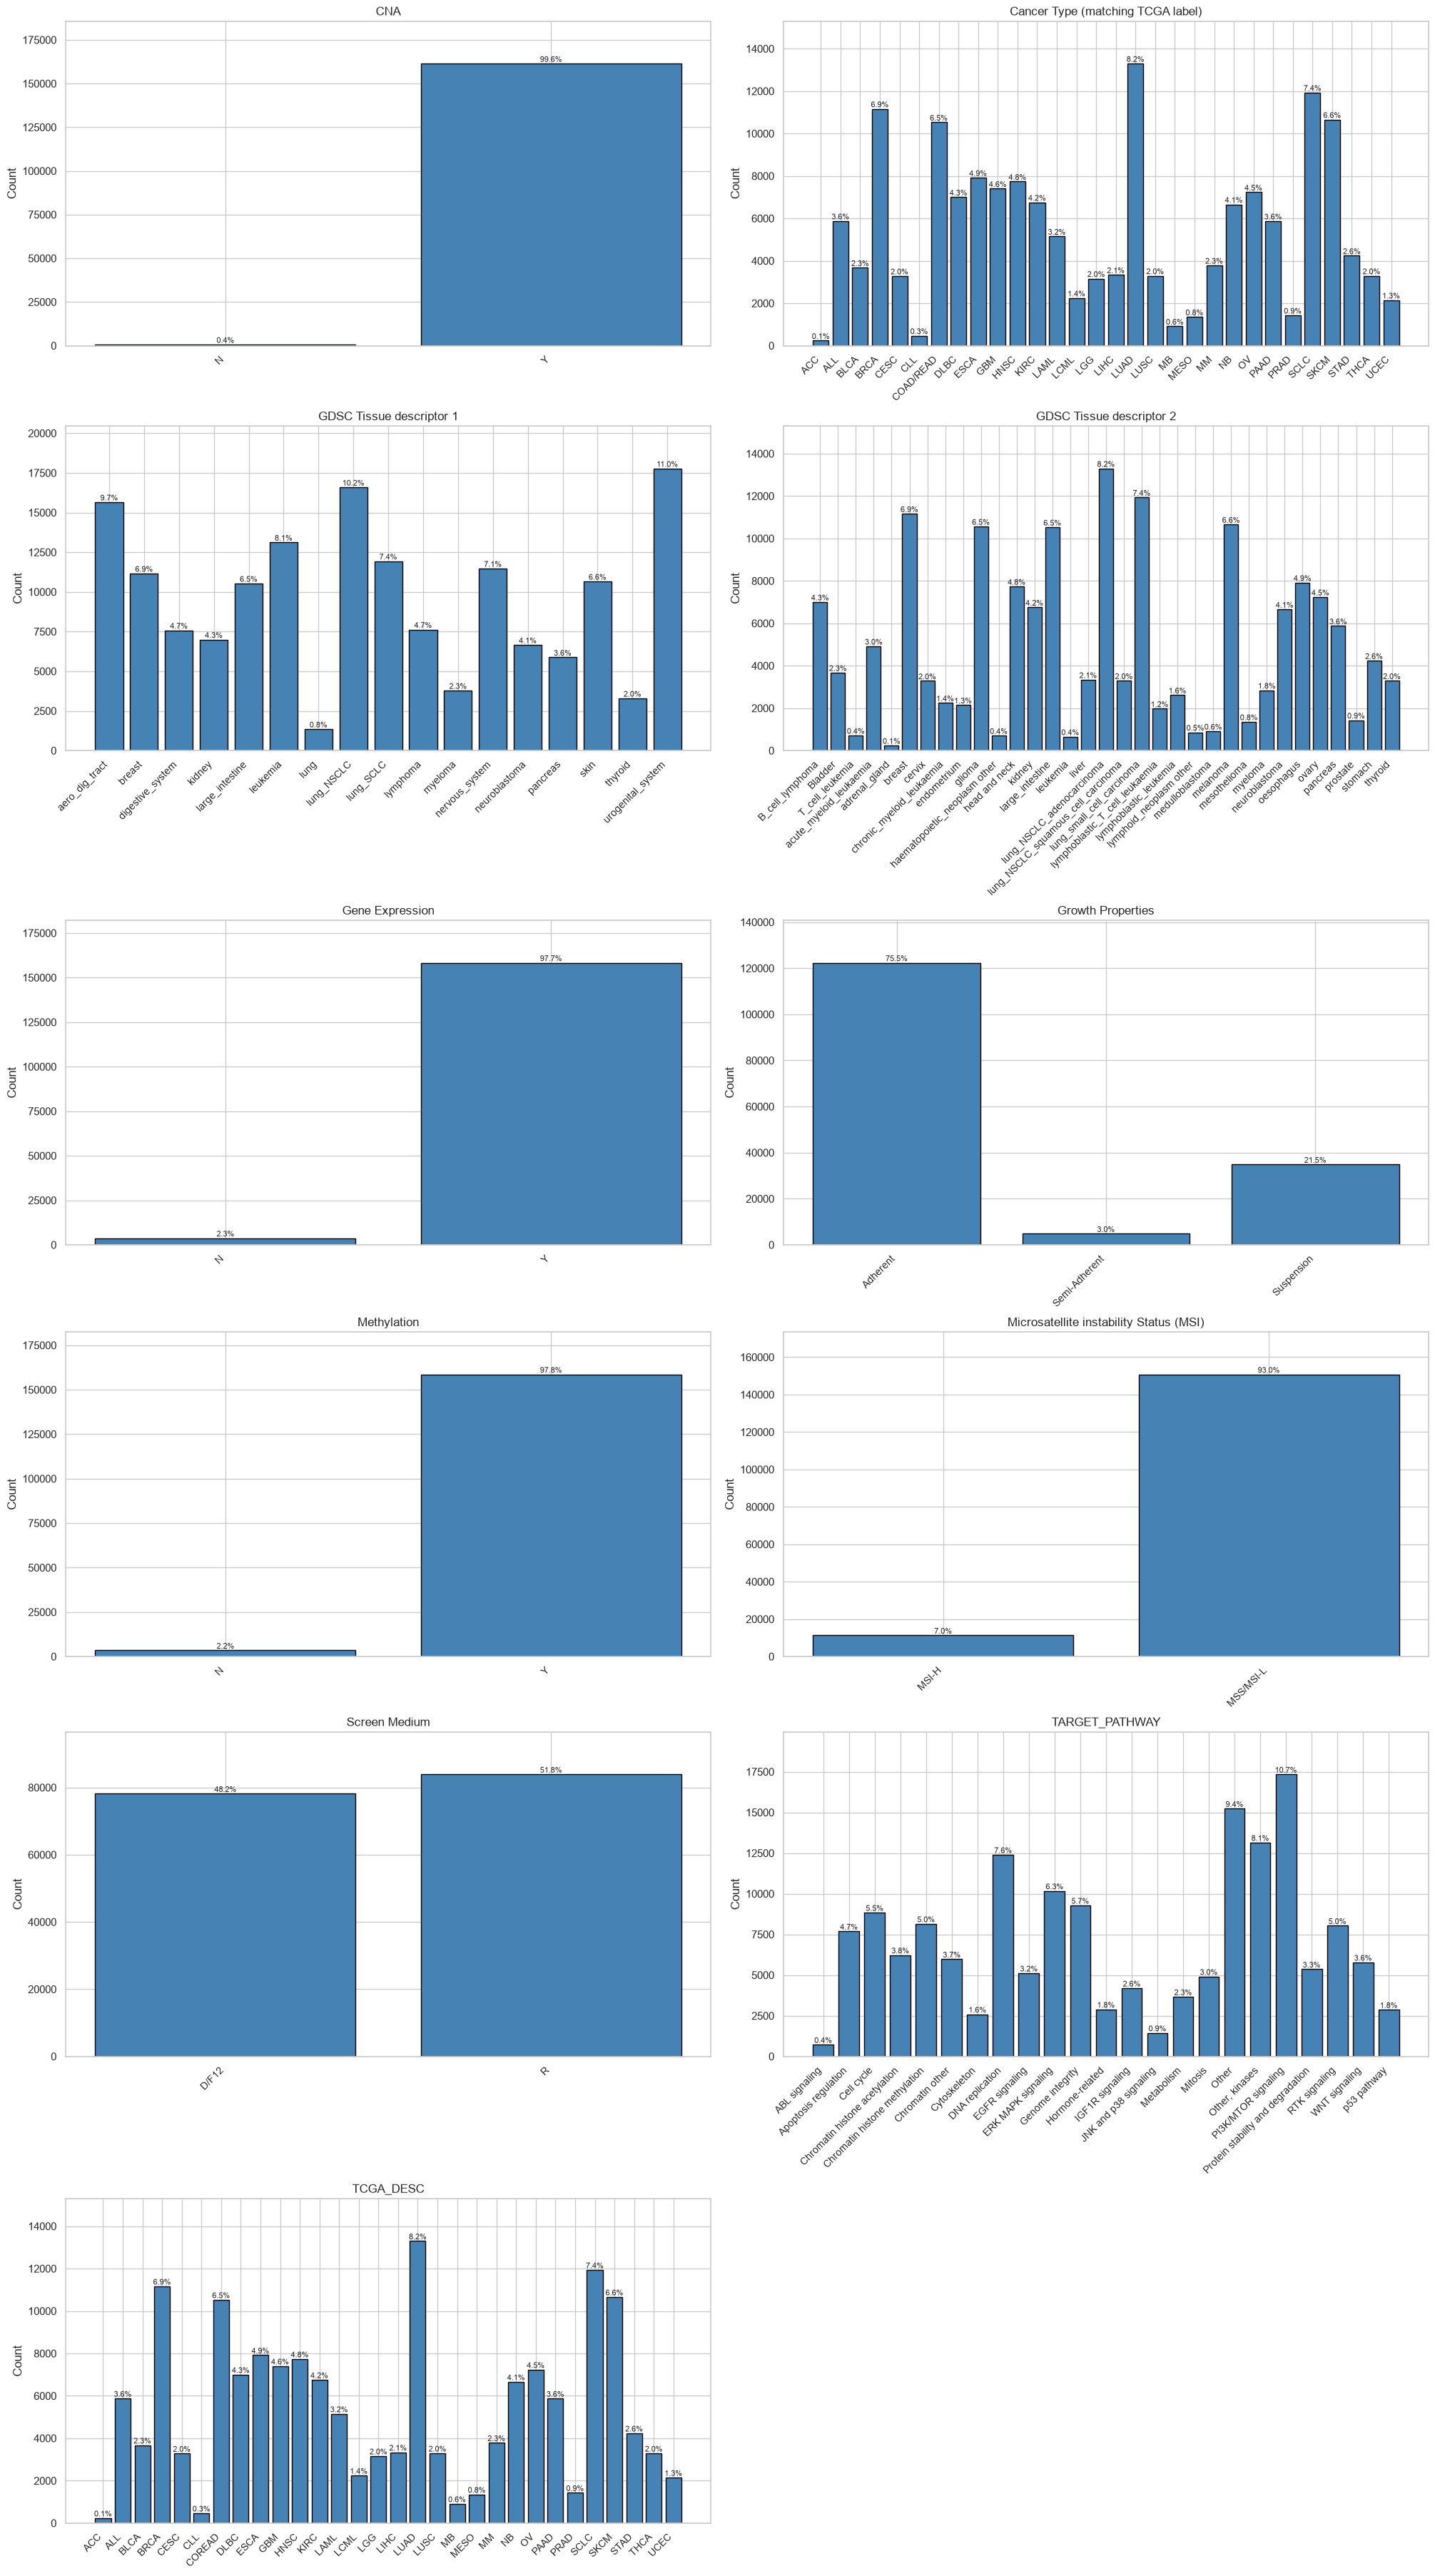

In [25]:
# Generate visualization for exploratory data analysis
plot_proportions(data=gdsc, columns=discretes, n_cols=2)

#### Several categorical variables show unequal representation across the dataset. MSS/MSI-L cell lines are more abundant than MSI-H cell lines, indicating that microsatellite-stable tumors dominate the screening collection. Some cancer types and target pathways are also more frequently represented.

## Multivariate Analysis

### Continuous

In [26]:
# Generate visualization for exploratory data analysis
def plot_correlation(data: pd.DataFrame, columns: list, screen_w, screen_h, title="Correlation Matrix (Lower Triangle)"):
    """
    Plots correlation heatmap with the upper triangle masked.
    
    Parameters:
    - data: The dataframe containing the data.
    - columns: List of column names to include in the analysis. 
    - screen_w, screen_h: Figure dimensions.
    """
    
    if data is None or columns is None:
        print("❌ Missing dataframe or columns")
        return

    # 1. Calculate Correlation
    corr_matrix = data[columns].corr()

    # 2. Create a Mask for the Upper Triangle
    # np.triu returns the upper triangle of an array.
    # The mask should be True for the values you want to HIDE.
    # mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
    mask = None

    # 3. Setup Plot 
    plt.figure(figsize=(screen_w, screen_h))
    plt.title(title)

    # 4. Render with Mask
    # Note: mask=mask argument hides the upper triangle
    sns.heatmap(corr_matrix, mask=mask, square=True, annot=True, cmap='coolwarm', center= 0, linewidths=0.5, fmt='.2f')
    
    plt.show()

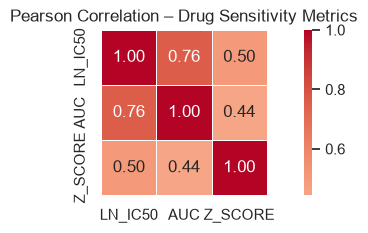

In [27]:
# Generate visualization for exploratory data analysis
plot_correlation(data=gdsc, columns=continuous, screen_h=SCREEN_H / 2.5, screen_w=SCREEN_W, title="Pearson Correlation – Drug Sensitivity Metrics")

#### The correlation matrix evaluates relationships between drug sensitivity metrics. Strong correlations indicate that some measures capture similar aspects of drug response, whereas weaker correlations suggest complementary information.

### Discretes - Continuous

In [28]:
# Aggregate and summarize data across groups
drug_stats = (
    gdsc.groupby("DRUG_NAME")[["LN_IC50", "AUC", "Z_SCORE"]]
    .agg(["median", "std", "count"])
    .round(3)
)

drug_stats.columns = ["_".join(c) for c in drug_stats.columns]
drug_stats = drug_stats.reset_index()
drug_stats

,DRUG_NAME,LN_IC50_median,LN_IC50_std,LN_IC50_count,AUC_median,AUC_std,AUC_count,Z_SCORE_median,Z_SCORE_std,Z_SCORE_count
0,5-Fluorouracil,4.462,1.703,737,0.928,0.080,737,0.044,0.992,737
1,5-azacytidine,2.893,1.368,574,0.848,0.085,574,-0.069,0.985,574
2,A-366,4.927,1.016,574,0.971,0.019,574,0.054,0.991,574
3,ABT737,2.278,2.069,726,0.854,0.187,726,0.195,1.008,726
4,AGI-5198,4.712,0.915,727,0.969,0.018,727,0.013,1.012,727
...,...,...,...,...,...,...,...,...,...,...
241,YK-4-279,2.123,1.668,727,0.813,0.116,727,-0.073,1.011,727
242,ZM447439,2.538,1.704,715,0.872,0.102,715,-0.023,1.000,715
243,alpha-lipoic acid,7.705,1.002,572,0.976,0.017,572,0.057,1.038,572
244,ascorbate (vitamin C),10.450,1.288,567,0.977,0.034,567,0.156,1.005,567


# 4. Drug Sensitivity Patterns

### Most Effective Drugs
We rank all drugs by **median LN_IC50 across all cell lines** and display the 10 most potent. These are drugs that inhibit 50 % of cell growth at the lowest concentration — candidates of high pharmacological interest.

Error bars (±1 SD) are shown to distinguish drugs that are universally potent from those that are potent only in a subset of cell lines.

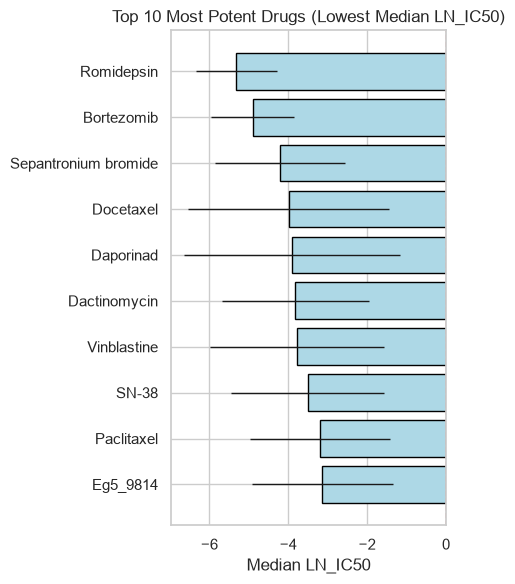

In [31]:
# visualization for top 10 most potent drugs
top_effective = drug_stats.nsmallest(10, "LN_IC50_median")

fig, ax = plt.subplots(figsize=(SCREEN_W * .5, 6))
bars = ax.barh(top_effective["DRUG_NAME"], top_effective["LN_IC50_median"],
               xerr=top_effective["LN_IC50_std"], color="lightblue",
               error_kw={"elinewidth": 1}, edgecolor="black")
ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Median LN_IC50")
ax.set_title("Top 10 Most Potent Drugs (Lowest Median LN_IC50)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

#### Drugs with the lowest median LN_IC50 values were considered the most potent (which means Romidepsin is the most potent drug here), as lower LN_IC50 indicates inhibition of cancer cell growth at lower concentrations. These compounds may represent promising therapeutic candidates across multiple cancer cell lines.

### Least Effective Drugs

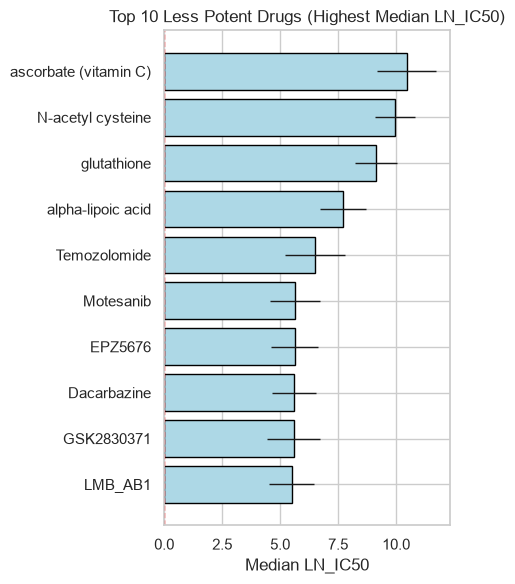

In [32]:
# visualization for top 10 least potent drugs
top_effective = drug_stats.nlargest(10, "LN_IC50_median")

fig, ax = plt.subplots(figsize=(SCREEN_W * .5, 6))

bars = ax.barh(top_effective["DRUG_NAME"], top_effective["LN_IC50_median"],
               xerr=top_effective["LN_IC50_std"], color="lightblue",
               error_kw={"elinewidth": 1}, edgecolor="black")

ax.axvline(0, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Median LN_IC50")
ax.set_title("Top 10 Less Potent Drugs (Highest Median LN_IC50)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

#### Drugs with the highest median LN_IC50 values were the least potent overall (which means ascorbate is the least potent drug here). These compounds require higher concentrations to achieve growth inhibition, suggesting reduced effectiveness across the screened cell lines.

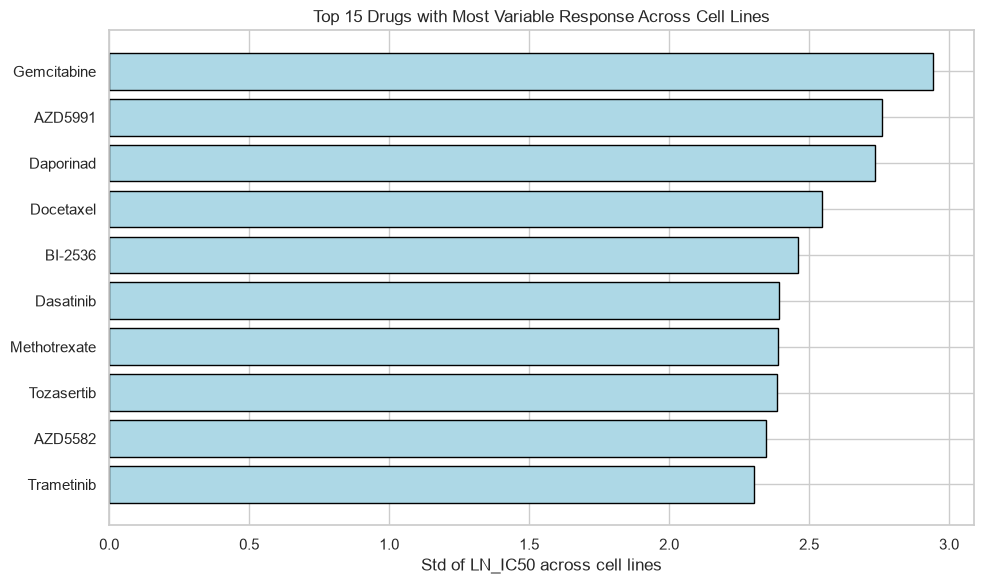

In [33]:
# visualization for drugs with Highly Variable Response Across Cell Lines
top_variable = drug_stats.nlargest(10, "LN_IC50_std")

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(top_variable["DRUG_NAME"], top_variable["LN_IC50_std"],
        color="lightblue", edgecolor="black")

ax.set_xlabel("Std of LN_IC50 across cell lines")
ax.set_title("Top 15 Drugs with Most Variable Response Across Cell Lines")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

#### Some drugs exhibited large variation in LN_IC50 values across cell lines. This suggests that sensitivity to these drugs depends strongly on cellular or genomic context, making them potential candidates for precision medicine approaches where treatment is tailored to specific tumor characteristics.

# 5. Cancer Cell Line Analysis

In [34]:
# Aggregate and summarize data across groups
results = (
gdsc.groupby(["DRUG_NAME", "CELL_LINE_NAME"])["LN_IC50"]
.mean()
.reset_index()
.rename(columns={"LN_IC50": "MEAN_LN_IC50"})
)

In [35]:
results

,DRUG_NAME,CELL_LINE_NAME,MEAN_LN_IC50
0,5-Fluorouracil,22RV1,2.319251
1,5-Fluorouracil,23132-87,1.807592
2,5-Fluorouracil,42-MG-BA,3.463196
3,5-Fluorouracil,451Lu,3.910357
4,5-Fluorouracil,639-V,4.575843
...,...,...,...
157808,glutathione,YAPC,10.129067
157809,glutathione,YH-13,9.473305
157810,glutathione,YT,8.883967
157811,glutathione,ZR-75-30,11.193687


In [40]:
# Initialize an empty list to store results
# Each entry will represent the average drug response for a specific cell line
results = []

# Loop through each unique drug in the dataset
for drug in gdsc["DRUG_NAME"].unique():
    
    # Subset the dataset to include only rows for the current drug
    subset = gdsc[gdsc["DRUG_NAME"] == drug]
    
    # Loop through each unique cell line tested with this drug
    for cell in subset["CELL_LINE_NAME"].unique():
        
        # Further subset the data for the current cell line
        cell_data = subset[subset["CELL_LINE_NAME"] == cell]
        
        # Compute the mean LN_IC50 for this drug-cell line combination
        # LN_IC50 represents drug sensitivity (lower = more sensitive)
        mean_response = cell_data["LN_IC50"].mean()
        
        # Store the result as a dictionary
        # This structure makes it easy to convert into a DataFrame later
        results.append({
            "DRUG_NAME": drug,
            "CELL_LINE": cell,
            "MEAN_LN_IC50": mean_response
        })

# Convert the list of dictionaries into a pandas DataFrame
# Final table: each row = one drug–cell line pair with average response
cell_drug_df = pd.DataFrame(results)

cell_drug_df

,DRUG_NAME,CELL_LINE,MEAN_LN_IC50
0,Camptothecin,PFSK-1,-1.463887
1,Camptothecin,COLO-829,-1.235034
2,Camptothecin,RT4,-2.963191
3,Camptothecin,SW780,-1.449138
4,Camptothecin,TCCSUP,-2.350633
...,...,...,...
157808,N-acetyl cysteine,MM1S,9.316959
157809,N-acetyl cysteine,SNU-175,10.127082
157810,N-acetyl cysteine,SNU-407,8.576377
157811,N-acetyl cysteine,SNU-61,10.519636


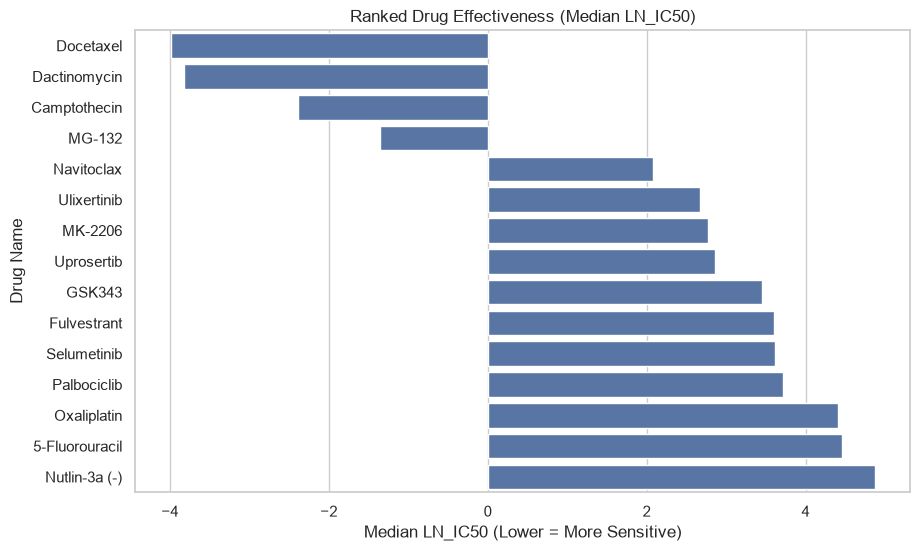

In [41]:
# Group the dataset by drug name and compute median LN_IC50
# This gives an overall measure of drug effectiveness across all cancer types
drug_response = gdsc.groupby("DRUG_NAME")["LN_IC50"].median()

# Select the top 15 most frequently tested drugs (to reduce noise)
top_drugs = gdsc["DRUG_NAME"].value_counts().head(15).index

# Filter only these drugs
drug_response = drug_response.loc[top_drugs]

# Sort values:
# Lower LN_IC50 = more effective → so sort ascending
drug_response = drug_response.sort_values(ascending=True)

# Create the plot
plt.figure(figsize=(10,6))

# Horizontal bar plot (best for ranking)
sns.barplot(
    x=drug_response.values,
    y=drug_response.index
)

# Add labels and title
plt.title("Ranked Drug Effectiveness (Median LN_IC50)")
plt.xlabel("Median LN_IC50 (Lower = More Sensitive)")
plt.ylabel("Drug Name")

# Show plot
plt.show()

#### Drug Effectiveness Ranking
Drug effectiveness varied substantially across treatments. Lower median LN_IC50 values indicate greater sensitivity, while higher values suggest resistance. These differences highlight the importance of selecting therapies based on observed drug response patterns.

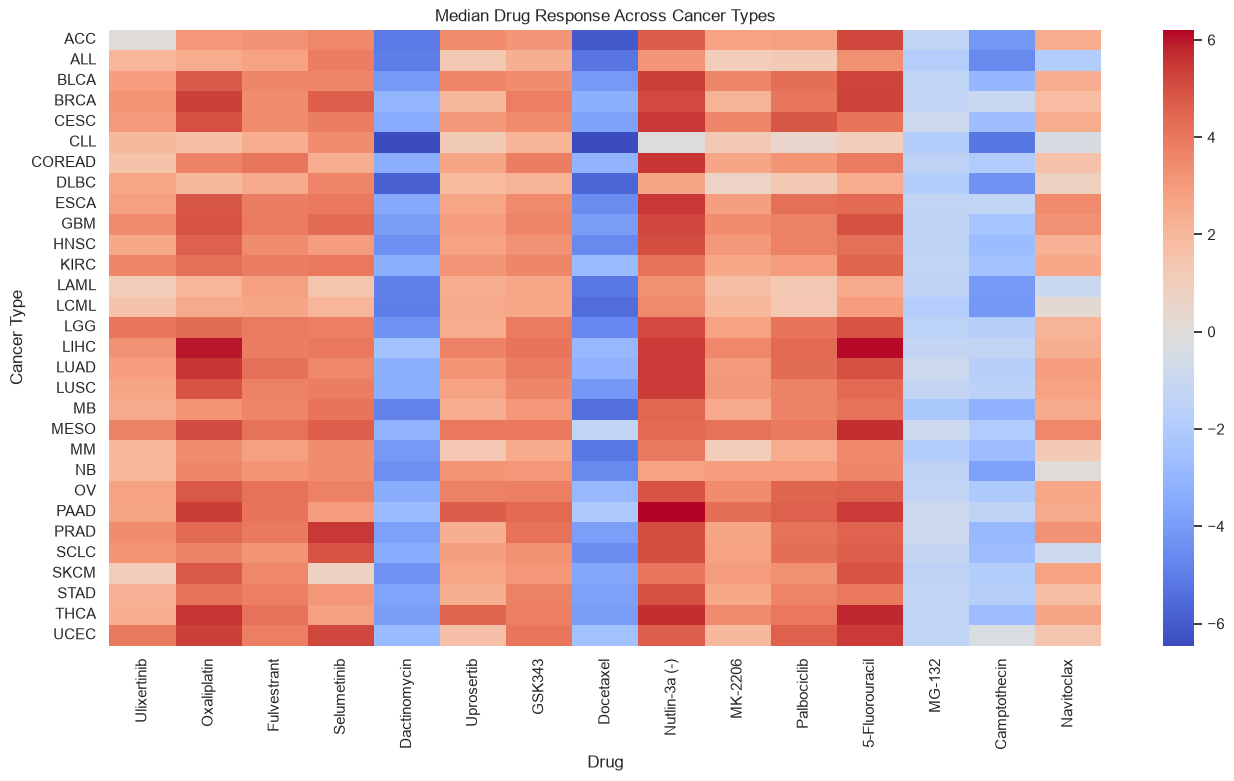

In [42]:
# Group the dataset by cancer type (TCGA_DESC) and drug name
# Then compute the median LN_IC50 for each combination
# Median is used instead of mean to reduce the effect of outliers
response_matrix = gdsc.groupby(
    ["TCGA_DESC", "DRUG_NAME"]
)["LN_IC50"].median().unstack()

# At this point:
# Rows   = Cancer types
# Columns = Drugs
# Values = Median drug response (LN_IC50)

# Optional step: select only the top 15 most frequently tested drugs
# This helps reduce noise and makes the heatmap easier to interpret
top_drugs = gdsc["DRUG_NAME"].value_counts().head(15).index

# Filter the response matrix to include only these top drugs
response_matrix = response_matrix[top_drugs]

# Create a figure with a larger size for better readability
plt.figure(figsize=(16,8))

# Plot the heatmap
# Each cell represents the median LN_IC50 for a drug-cancer combination
# "coolwarm" color map:
#   - Cool colors (blue) → lower LN_IC50 → higher drug sensitivity
#   - Warm colors (red) → higher LN_IC50 → lower sensitivity (resistance)
sns.heatmap(response_matrix, cmap="coolwarm")

# Add descriptive title and axis labels
plt.title("Median Drug Response Across Cancer Types")
plt.xlabel("Drug")
plt.ylabel("Cancer Type")

# Display the plot
plt.show()

#### Drug Response Across Cancer Types Heatmap
Drug sensitivity differed across cancer types. Some cancer types showed consistently lower LN_IC50 values, indicating increased sensitivity to treatment, while others appeared more resistant. This suggests that cancer lineage influences therapeutic response.

### LN_IC50 Distribution by Cancer Type

A **box plot sorted by median LN_IC50** lets us rank cancer types from most drug-sensitive (left) to most drug-resistant (right) globally. The red dashed line marks the overall median across all rows, serving as a neutral reference point.

Note that this global view aggregates across all drugs — a cancer type that appears resistant overall may still harbour a narrow but targetable sensitivity to specific agents (explored in the heatmap and selective sensitivity analysis below).

C:\Users\User\AppData\Local\Temp\ipykernel_24336\530419225.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=gdsc, x="TCGA_DESC", y="LN_IC50", order=cancer_order,
C:\Users\User\AppData\Local\Temp\ipykernel_24336\530419225.py:15: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)


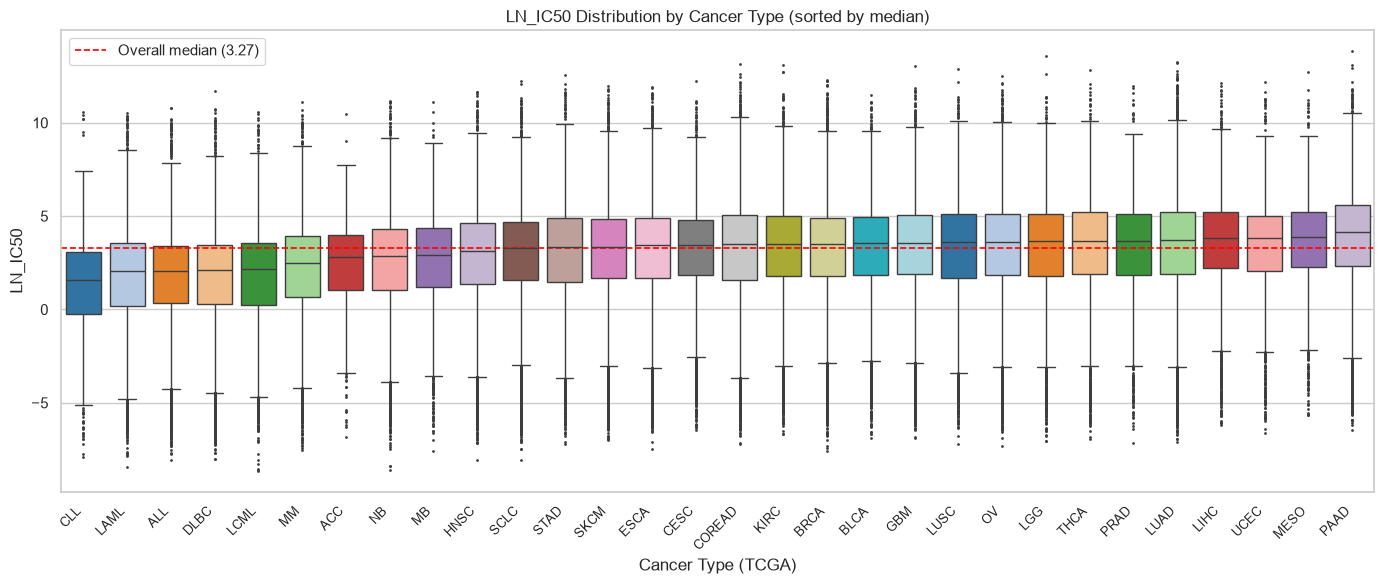

In [44]:
# Generate visualization for exploratory data analysis
cancer_order = (
    gdsc.groupby(["TCGA_DESC"])["LN_IC50"]
    .median()
    .sort_values()
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=gdsc, x="TCGA_DESC", y="LN_IC50", order=cancer_order,
            palette="tab20", fliersize=1, ax=ax)

ax.axhline(gdsc["LN_IC50"].median(), color="red", linestyle="--",
           linewidth=1.2, label=f"Overall median ({gdsc['LN_IC50'].median():.2f})")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)
ax.set_title("LN_IC50 Distribution by Cancer Type (sorted by median)")
ax.set_xlabel("Cancer Type (TCGA)")
ax.set_ylabel("LN_IC50")
ax.legend()
plt.tight_layout()
plt.show()

#### In Conclusion
Cancer types displayed distinct distributions of LN_IC50 values.
Tumors with lower median LN_IC50 values were generally more drug-sensitive, whereas those with higher values exhibited greater resistance (in this case, the most drug-sensitive cell types are the **CLL Types** while the least sensitive are the **PAAD Types**).
These findings demonstrate heterogeneity in treatment response among cancers.

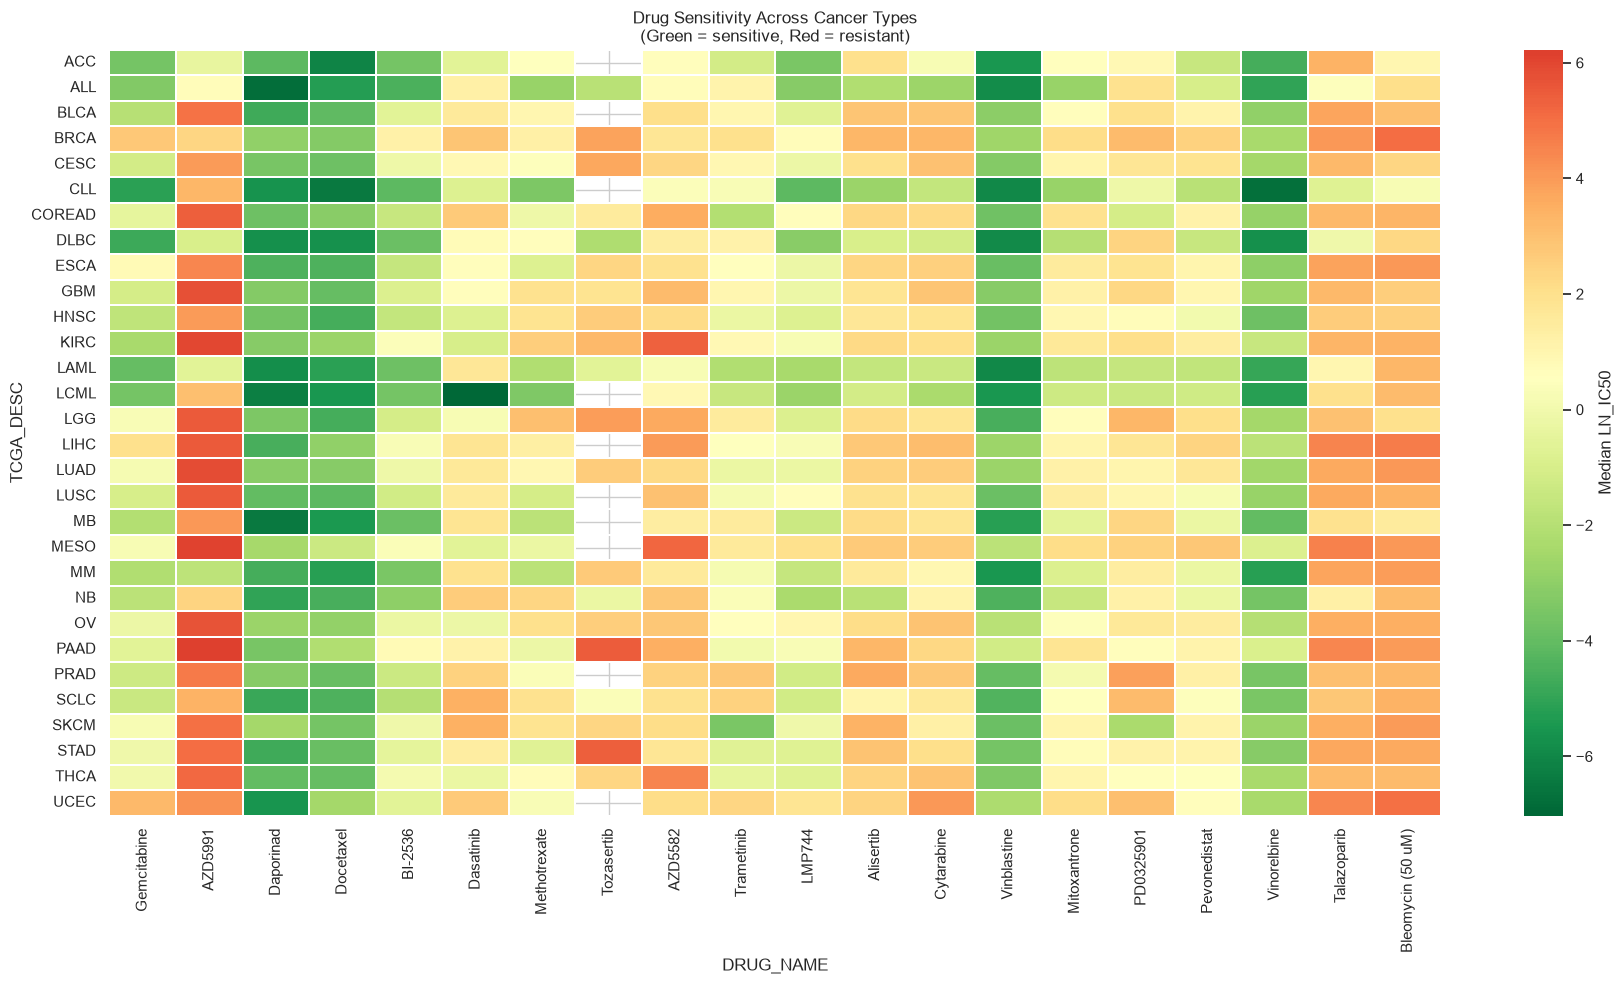

In [45]:
# Generate visualization for exploratory data analysis
pivot = (
    gdsc.groupby(["TCGA_DESC", "DRUG_NAME"])["LN_IC50"]
    .median()
    .unstack("DRUG_NAME")
)

# Optional: reduce to top variable drugs (important!)
top_drugs = gdsc.groupby("DRUG_NAME")["LN_IC50"].std().nlargest(20).index
pivot = pivot[top_drugs]

fig, ax = plt.subplots(figsize=(18, 10))

sns.heatmap(
    pivot,
    cmap="RdYlGn_r",
    center=pivot.stack().median(),
    linewidths=0.2,
    cbar_kws={"label": "Median LN_IC50"},
    ax=ax
)

ax.set_title("Drug Sensitivity Across Cancer Types\n(Green = sensitive, Red = resistant)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

#### Drug Sensitivity Across Cancer Types (Heatmap Above)
From the heatmap above showing the drug sensitivity across cancer types; the greener the cells, the higher the sensitivy of the cancer type against each drugs. While redder the cells, the higher the resistance of the cancer types/tumors against each drugs.
Certain drugs demonstrated selective activity against specific cancer types. This pattern suggests that therapeutic effectiveness is influenced by the molecular characteristics of different tumor lineages and supports the development of targeted treatment strategies.

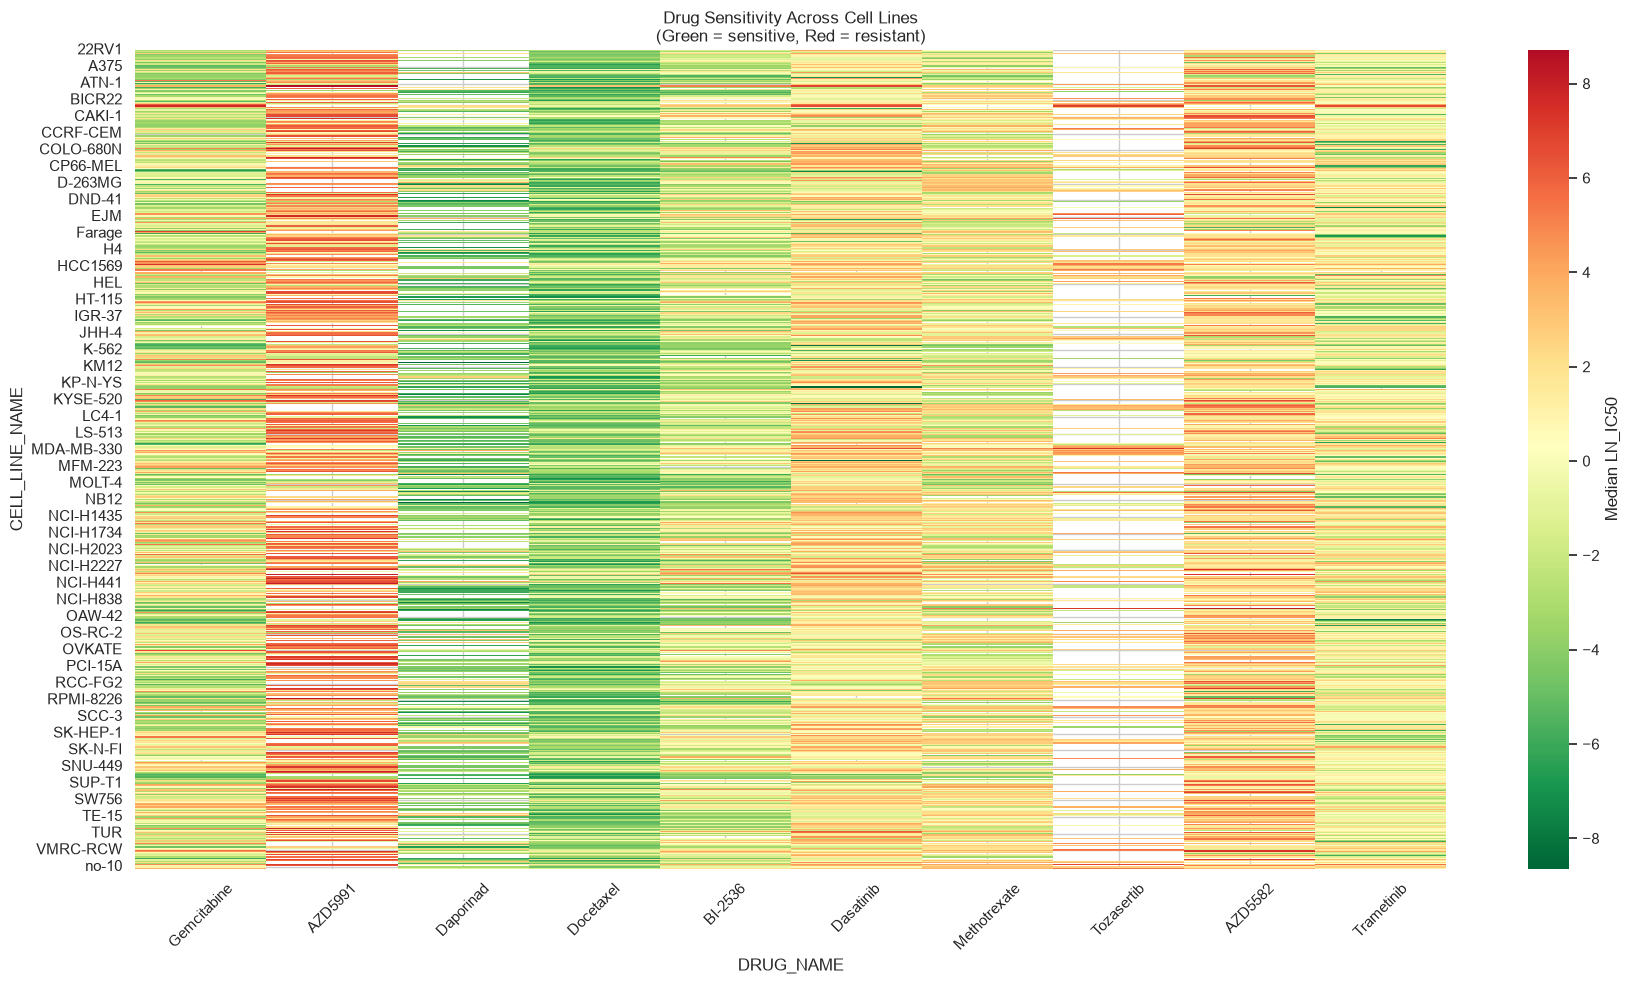

In [46]:
# Generate visualization for exploratory data analysis
pivot = (
    gdsc.groupby(["CELL_LINE_NAME", "DRUG_NAME"])["LN_IC50"]
    .median()
    .unstack("DRUG_NAME")
)

# Optional: reduce to top variable drugs (important!)
top_drugs = gdsc.groupby("DRUG_NAME")["LN_IC50"].std().nlargest(10).index
pivot = pivot[top_drugs]

fig, ax = plt.subplots(figsize=(18, 10))

sns.heatmap(
    pivot,
    cmap="RdYlGn_r",
    center=pivot.stack().median(),
    linewidths=0,
    cbar_kws={"label": "Median LN_IC50"},
    ax=ax
)

ax.set_title("Drug Sensitivity Across Cell Lines\n(Green = sensitive, Red = resistant)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### Drug Sensitivity Across Cell Lines
Considerable variability in drug response was observed among individual cell lines, even within the same cancer type. This indicates that factors beyond tissue origin, including genomic alterations, may influence treatment sensitivity.

## 6. Genomic, Transcriptomic, and Epigenomic Influence on Drug Response

In [47]:
genomic_flags = ["CNA", "Gene Expression", "Methylation", "Microsatellite instability Status (MSI)"]
sensitivity_metrics = ["LN_IC50", "AUC", "Z_SCORE"]

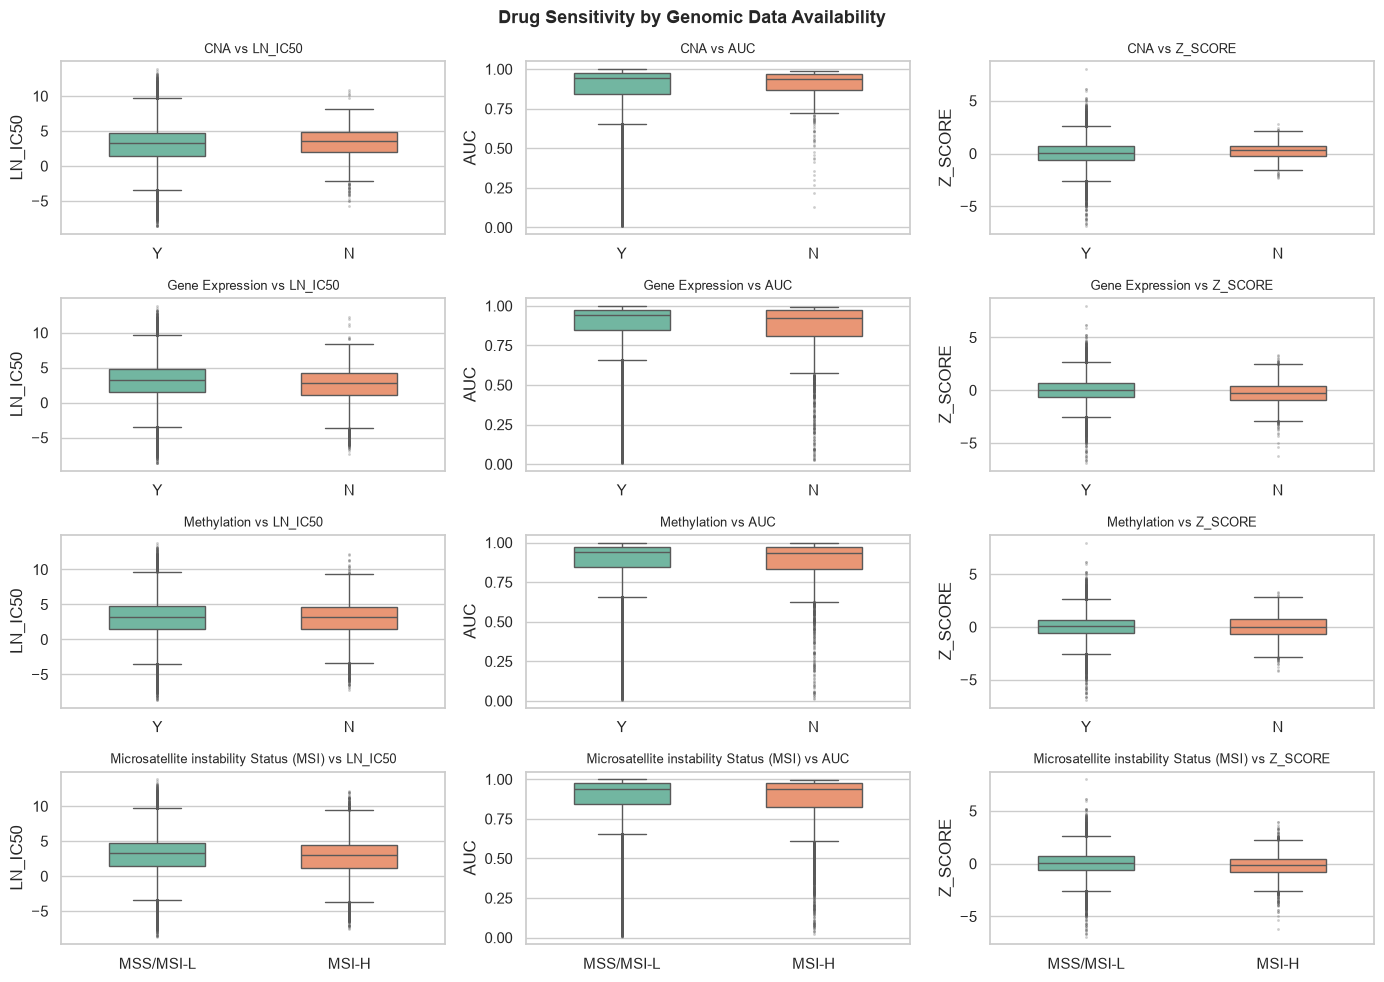

In [48]:
# Generate visualization for exploratory data analysis
fig, axes = plt.subplots(len(genomic_flags), len(sensitivity_metrics), figsize=(14, 10))

for i, flag in enumerate(genomic_flags):
    for j, metric in enumerate(sensitivity_metrics):
        ax = axes[i][j]
        sns.boxplot(data=gdsc, x=flag, y=metric, hue=flag, palette="Set2",legend=False,
                    width=0.5, flierprops=dict(marker=".", markersize=2, alpha=0.3), ax=ax)
        ax.set_title(f"{flag} vs {metric}", fontsize=9)
        ax.set_xlabel("")

plt.suptitle("Drug Sensitivity by Genomic Data Availability", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("genomic_flags_vs_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

#### Observations from the Plots Above
Drug response metrics (LN_IC50, AUC, Z_SCORE) varied across groups defined by CNA, Gene Expression, Methylation status, and MSI status. These observations suggest that genomic and epigenomic features may contribute to differences in treatment sensitivity among cancer cell lines.

In [51]:
import scipy
print(scipy.__version__)

1.18.1


In [52]:
# Import required libraries
# ttest_ind → used to compare means between two independent groups
# pandas → for data manipulation and DataFrame creation
from scipy.stats import ttest_ind

# Initialize a list to store results for each drug
# Each entry will contain statistical test results for multiple genomic features
results = []

# Define genomic/epigenomic features to test
# These represent biological factors that may influence drug response
features = ["CNA", "Gene Expression", "Methylation"]

# Loop through each unique drug in the dataset
for drug in gdsc["DRUG_NAME"].unique():
    
    # Subset data for the current drug
    subset = gdsc[gdsc["DRUG_NAME"] == drug]
    
    # Initialize a dictionary to store results for this drug
    # Will hold p-values and mean differences for each feature
    drug_result = {"DRUG_NAME": drug}
    
    # Loop through each genomic feature
    for feature in features:
        
        # Check if the feature has at least two groups (e.g., Yes/No, 0/1)
        # If not, statistical comparison is not possible
        if subset[feature].nunique() < 2:
            drug_result[feature + "_p"] = None      # No p-value available
            drug_result[feature + "_diff"] = None   # No difference calculated
            continue
        
        # Get the unique groups for the feature (e.g., mutated vs not mutated)
        groups = subset[feature].unique()
        
        # Split LN_IC50 values into two groups based on feature status
        # g1 and g2 represent two biological conditions
        g1 = subset[subset[feature] == groups[0]]["LN_IC50"]
        g2 = subset[subset[feature] == groups[1]]["LN_IC50"]
        
        # Compute the difference in mean drug response between the two groups
        # Positive/negative value indicates direction of effect
        diff = g1.mean() - g2.mean()
        
        # Perform independent t-test to check if the difference is statistically significant
        # stat → t-statistic
        # p → p-value (probability that observed difference is due to chance)
        stat, p = ttest_ind(g1, g2)
        
        # Store results:
        # diff → magnitude and direction of effect
        # p → statistical significance
        drug_result[feature + "_diff"] = diff
        drug_result[feature + "_p"] = p
    
    # Append results for this drug to the main results list
    results.append(drug_result)

# Convert the list of dictionaries into a DataFrame
# Each row represents a drug, with columns for each feature's statistics
multi_feature_df = pd.DataFrame(results)

# Preview the results
multi_feature_df.head()

,DRUG_NAME,CNA_diff,CNA_p,Gene Expression_diff,Gene Expression_p,Methylation_diff,Methylation_p
0,Camptothecin,0.481560,0.646084,0.320857,0.423930,0.152597,0.724269
1,Vinblastine,-0.795814,0.609865,-0.743470,0.735851,0.283926,0.734554
2,Cisplatin,-0.319934,0.802164,-2.172698,0.228258,-0.654884,0.307297
3,Cytarabine,-2.512486,0.111784,1.996983,0.371401,0.848055,0.317730
4,Docetaxel,-1.023860,0.369877,1.426749,0.010859,0.111533,0.831845


#### Statistical Testing (t-tests)
Statistical testing revealed that Gene Expression status showed the strongest association with drug response, with multiple drugs exhibiting significant differences in LN_IC50 between expression groups. This suggests that transcriptional activity may be an important determinant of treatment sensitivity across cancer cell lines. 
Copy Number Alterations (CNA) were associated with the response of a smaller subset of drugs, indicating that genomic structural changes may influence sensitivity in specific therapeutic contexts. 
Methylation status showed comparatively fewer significant associations, suggesting a weaker overall influence on drug response within this dataset.

In [54]:
# Filter the DataFrame to identify drugs that show a statistically significant association with at least one genomic feature
significant = multi_feature_df[
    (multi_feature_df["CNA_p"] < 0.05) |
    (multi_feature_df["Gene Expression_p"] < 0.05) |
    (multi_feature_df["Methylation_p"] < 0.05)
]

significant.head(20)

,DRUG_NAME,CNA_diff,CNA_p,Gene Expression_diff,Gene Expression_p,Methylation_diff,Methylation_p
4,Docetaxel,-1.023860,0.369877,1.426749,0.010859,0.111533,0.831845
5,Methotrexate,-1.310892,0.343414,-2.011790,0.000136,-1.390611,0.017703
9,Vorinostat,-0.382679,0.552080,0.533026,0.030215,-0.080198,0.768948
22,Tanespimycin,-2.338628,0.010089,-0.085285,0.806805,-0.147167,0.695399
31,NU7441,0.619786,0.431575,0.812119,0.006970,0.112267,0.729932
33,Doramapimod,0.280654,0.679729,1.097585,0.000022,0.463465,0.098138
34,JNK Inhibitor VIII,0.262754,0.637561,0.569906,0.008977,0.198982,0.387102
35,Wee1 Inhibitor,-0.597500,0.504809,0.822183,0.016301,0.417657,0.271652
37,Mirin,-1.193844,0.076534,0.730921,0.005622,0.356240,0.227048
39,ZM447439,-0.043726,0.964654,1.119539,0.002951,-0.093848,0.817701


In [55]:
# Convert wide format → long format
volcano_data = []

features = ["CNA", "Gene Expression", "Methylation"]

for _, row in multi_feature_df.iterrows():
    for feature in features:
        volcano_data.append({
            "DRUG_NAME": row["DRUG_NAME"],
            "Feature": feature,
            "Effect_Size": row[feature + "_diff"],   # mean difference
            "p_value": row[feature + "_p"]
        })

volcano_df = pd.DataFrame(volcano_data)

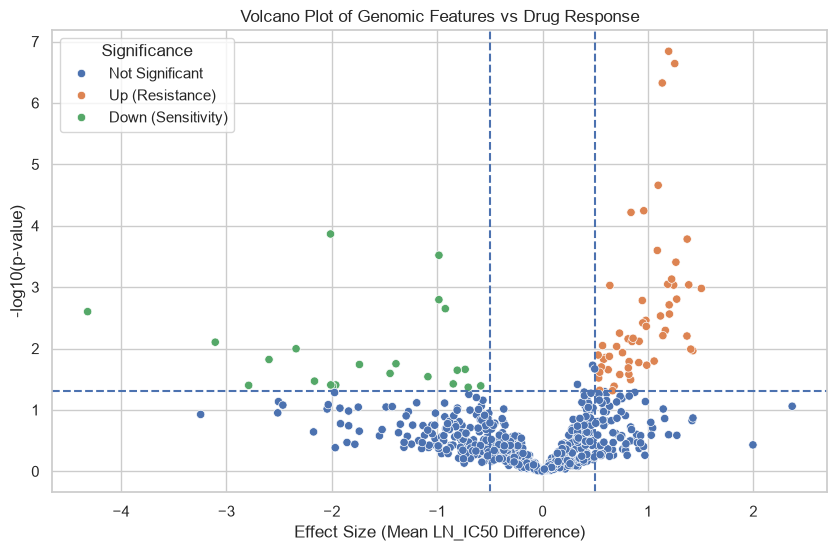

In [56]:
# Remove missing values
volcano_df = volcano_df.dropna()

# Convert p-values to -log10(p)
volcano_df["neg_log10_p"] = -np.log10(volcano_df["p_value"])

# Common thresholds
p_thresh = 0.05
effect_thresh = 0.5  # adjust based on your data

# Create significance labels
volcano_df["Significance"] = "Not Significant"

volcano_df.loc[
    (volcano_df["p_value"] < p_thresh) & 
    (volcano_df["Effect_Size"] > effect_thresh),
    "Significance"
] = "Up (Resistance)"

volcano_df.loc[
    (volcano_df["p_value"] < p_thresh) & 
    (volcano_df["Effect_Size"] < -effect_thresh),
    "Significance"
] = "Down (Sensitivity)"

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=volcano_df,
    x="Effect_Size",
    y="neg_log10_p",
    hue="Significance"
)

# Add threshold lines
plt.axhline(-np.log10(p_thresh), linestyle="--")  # p-value cutoff
plt.axvline(effect_thresh, linestyle="--")        # effect size cutoff
plt.axvline(-effect_thresh, linestyle="--")

plt.title("Volcano Plot of Genomic Features vs Drug Response")
plt.xlabel("Effect Size (Mean LN_IC50 Difference)")
plt.ylabel("-log10(p-value)")

plt.show()

#### Interpretation for the Volcano Plot
The volcano plot identified several drug–genomic feature associations with both statistically significant p-values and substantial effect sizes.
Gene Expression produced the largest number of significant associations, highlighting its potential role as a predictive biomarker of drug response.
These findings support the concept of precision oncology, where molecular characteristics of tumors may help guide treatment selection.

### Overall Conclusion:
Analysis of the GDSC dataset revealed substantial variation in drug sensitivity across cancer cell lines and cancer types. 
Several drugs demonstrated strong potency, while others showed highly variable responses, indicating that treatment effectiveness is strongly dependent on biological context.

Drug response patterns differed between cancer types, suggesting that tissue lineage contributes to therapeutic sensitivity. 
Heatmap analyses further revealed selective responses, where certain drugs were particularly effective against specific cancer groups.
Statistical testing showed that Gene Expression was the genomic feature most frequently associated with significant changes in drug response, while CNA exhibited more limited but notable associations. Methylation demonstrated comparatively fewer significant relationships.

Together, these findings suggest that molecular features influence treatment sensitivity and support the use of biomarker-guided approaches in precision oncology.